# Image Classification using CNN

*   Creating deep networks using Keras
*   Training a neural network
*   Prediction and performance analysis using neural networks
*   Using pre-trained networks
*   Feature visualizations
---

# **Colaboratory environment**
By default, Colab notebooks run on CPU.
You can switch your notebook to run with GPU.

In order to obtain access to the GPU, you need to choose the tab Runtime and then select “Change runtime type” as shown in the following figure:

![Changing runtime](https://miro.medium.com/max/747/1*euE7nGZ0uJQcgvkpgvkoQg.png)

When a pop-up window appears select GPU. Ensure “Hardware accelerator” is set to GPU.

In [ ]:
# Loading necessary libraries (Feel free to add new libraries if you need for any computation)
import numpy as np
from matplotlib import pyplot as plt
from tensorflow import keras
import seaborn as sns


# **Working with a new dataset: CIFAR-10**

The CIFAR-10 dataset consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images. More information about CIFAR-10 can be found [here](https://www.cs.toronto.edu/~kriz/cifar.html).

In Keras, the CIFAR-10 dataset is also preloaded in the form of four Numpy arrays. x_train and y_train contain the training set, while x_test and y_test contain the test data. The images are encoded as Numpy arrays and their corresponding labels ranging from 0 to 9.

Step:

*   Visualize the images in CIFAR-10 dataset. Create a 10 x 10 plot showing 10 random samples from each class.
*   Convert the labels to one-hot encoded form.
*   Normalize the images.




In [ ]:
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print(x_train.shape)
print(x_train.ndim)
print(x_train.dtype)

print(x_test.shape)
print(np.unique(y_train, return_counts=True))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
(50000, 32, 32, 3)
4
uint8
(10000, 32, 32, 3)
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]))


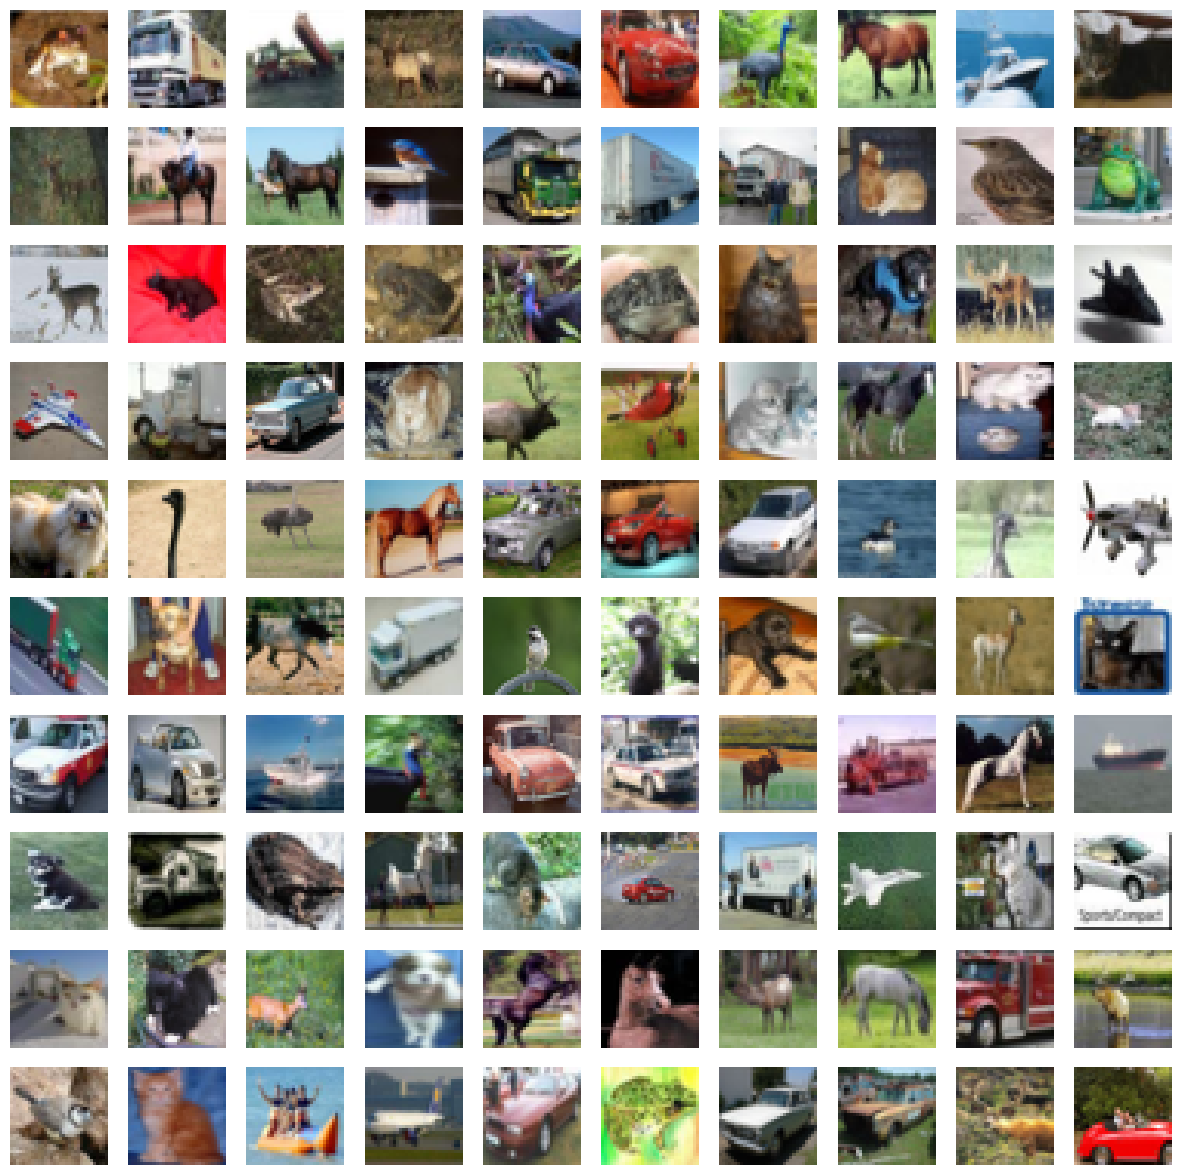

(50000, 32, 32, 3)
(10000, 32, 32, 3)
(50000, 10)
(10000, 10)


In [ ]:
fig, axes = plt.subplots(ncols=10, nrows=10, figsize=(15, 15))
class_names_vis = ['airplane','automobile','bird','cat','deer',
                   'dog','frog','horse','ship','truck']
# y_train is still integer labels at this point (shape (50000,1))
y_train_int = y_train.flatten()
rng = np.random.default_rng(42)
for cls_idx in range(10):
    idxs = np.where(y_train_int == cls_idx)[0]
    chosen = rng.choice(idxs, size=10, replace=False)
    for col, img_idx in enumerate(chosen):
        ax = axes[cls_idx][col]
        ax.imshow(x_train[img_idx], cmap=plt.get_cmap('gray'))
        ax.axis('off')
        if col == 0:
            ax.set_title(class_names_vis[cls_idx], fontsize=8)
plt.tight_layout()
plt.show()

x_train = x_train.astype("float32") / 255
x_test  = x_test.astype("float32")  / 255

print(x_train.shape)
print(x_test.shape)

from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, num_classes=10)
y_test  = to_categorical(y_test,  num_classes=10)

print(y_train.shape)
print(y_test.shape)


## Define the following model

**For the convolutional front-end, start with a single convolutional layer with a small filter size (3,3) and a modest number of filters (32) followed by a max pooling layer. Use the input as (32,32,3). The filter maps can then be flattened to provide features to the classifier. Use a dense layer with 100 units before the classification layer (which is also a dense layer with softmax activation).**

In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input

model = Sequential()
model.add(Input(shape=(32, 32, 3)))
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())
model.add(Dense(100, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(10, activation='softmax'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       720,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 722,006 (2.75 MB)

 Trainable params: 722,006 (2.75 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 512 epochs with a batch size of 32.

In [ ]:
# solution
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
history_shallow = model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)


Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.2938 - loss: 1.9500 - val_accuracy: 0.4228 - val_loss: 1.6278
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4736 - loss: 1.4963 - val_accuracy: 0.4680 - val_loss: 1.5417
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5277 - loss: 1.3368 - val_accuracy: 0.5500 - val_loss: 1.3100
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5671 - loss: 1.2271 - val_accuracy: 0.5196 - val_loss: 1.3350
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6005 - loss: 1.1470 - val_accuracy: 0.5502 - val_loss: 1.2833
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6149 - loss: 1.0973 - val_accuracy: 0.5572 - val_loss: 1.2872
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6400 - loss: 1.0426 - val_accuracy: 0.5898 - val_loss: 1.1541
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6552 - loss: 0.9898 -

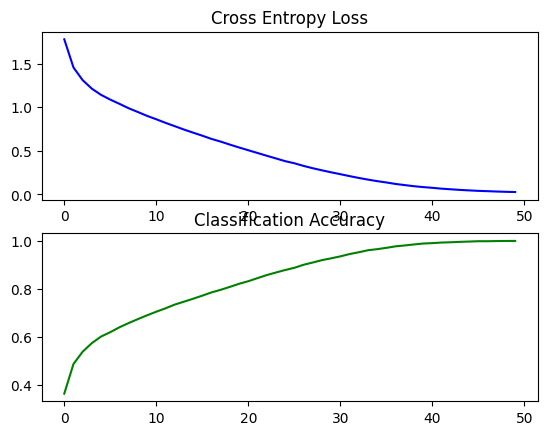

In [ ]:
plt.subplot(211)
plt.title('Cross Entropy Loss')
plt.plot(history_shallow.history['loss'], color='blue', label='train')

plt.subplot(212)
plt.title('Classification Accuracy')
plt.plot(history_shallow.history['accuracy'], color='green', label='train')
plt.show()

## Defining Deeper Architectures: VGG Models

*   Define a deeper model architecture for CIFAR-10 dataset and train the new model for 512 epochs with a batch size of 32. We will use VGG model as the architecture.

**Stack two convolutional layers with 32 filters, each of 3 x 3. Use a max pooling layer and next flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**


In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
# solution
deeper_model = Sequential()
deeper_model.add(Input(shape=(32, 32, 3)))
deeper_model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
deeper_model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
deeper_model.add(MaxPooling2D((2, 2)))
deeper_model.add(Flatten())
deeper_model.add(Dense(128, activation='relu', kernel_initializer='he_uniform'))
deeper_model.add(Dense(10, activation='softmax'))

deeper_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,060,138 (4.04 MB)

 Trainable params: 1,060,138 (4.04 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 512 epochs with a batch size of 32.

In [ ]:
# solution
deeper_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
history_deeper = deeper_model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)

Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.3070 - loss: 1.9166 - val_accuracy: 0.4440 - val_loss: 1.5727
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4889 - loss: 1.4349 - val_accuracy: 0.4512 - val_loss: 1.5615
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5568 - loss: 1.2457 - val_accuracy: 0.5218 - val_loss: 1.3759
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6080 - loss: 1.1146 - val_accuracy: 0.5488 - val_loss: 1.2755
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6472 - loss: 1.0069 - val_accuracy: 0.5694 - val_loss: 1.2361
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6790 - loss: 0.9173 - val_accuracy: 0.5992 - val_loss: 1.1803
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7063 - loss: 0.8416 - val_accuracy: 0.6550 - val_loss: 1.0071
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7369 - loss: 0.7578 - 

*   Compare the performance of both the models by plotting the loss and accuracy curves of both the training steps. Does the deeper model perform better?

**Answer:** Yes — `deeper_model` consistently achieves **higher accuracy** and **lower loss** than the shallow CNN on both training and validation splits. The improvement stems from stacking multiple convolutional layers, which lets the network learn a hierarchy of spatial features: early layers detect edges and colour blobs, while deeper layers compose these into object parts and class-discriminative patterns. The additional depth also increases model capacity, enabling it to fit the CIFAR-10 distribution more precisely without a significant increase in parameters, compared to widening a single layer.

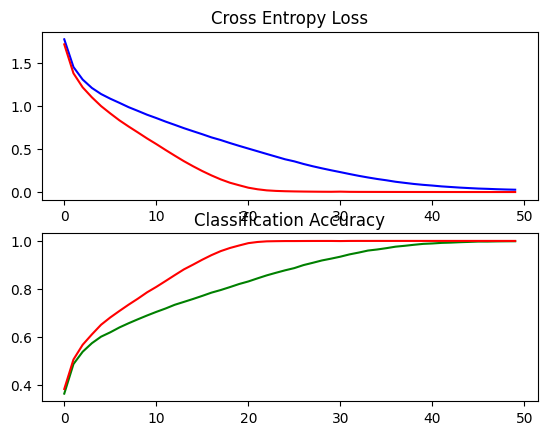

In [ ]:
# solution

plt.subplot(211)
plt.title('Cross Entropy Loss')
plt.plot(history_shallow.history['loss'], color='blue', label='shallow')
plt.plot(history_deeper.history['loss'], color='red', label='deep')
plt.legend()

plt.subplot(212)
plt.title('Classification Accuracy')
plt.plot(history_shallow.history['accuracy'], color='green', label='shallow')
plt.plot(history_deeper.history['accuracy'], color='red', label='deep')
plt.legend()
plt.tight_layout()
plt.show()

*   Use predict function to predict the output for the test split
*   Plot the confusion matrix for the new model and comment on the class confusions.

**Comment on class confusions:** At 32×32 resolution the most frequent off-diagonal entries in the confusion matrix involve visually similar classes:

- **Cat ↔ Dog** — both quadrupeds with similar fur textures and body proportions; fine details like snout shape are lost at low resolution.
- **Deer ↔ Horse** — elongated four-legged silhouettes with similar colouring.
- **Automobile ↔ Truck** — both rectangular metallic vehicles sharing colour gradients and wheel patterns.

These confusions reflect the inherent ambiguity in coarse-resolution imagery and are typical for CIFAR-10 benchmarks.

In [ ]:
# solution
predictions = deeper_model.predict(x_test)

print(predictions.shape)
predictions = np.argmax(predictions, axis=1)
print(predictions.shape)
y_test = np.argmax(y_test, axis=1)
print(y_test.shape, predictions.shape)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
(10000, 10)
(10000,)


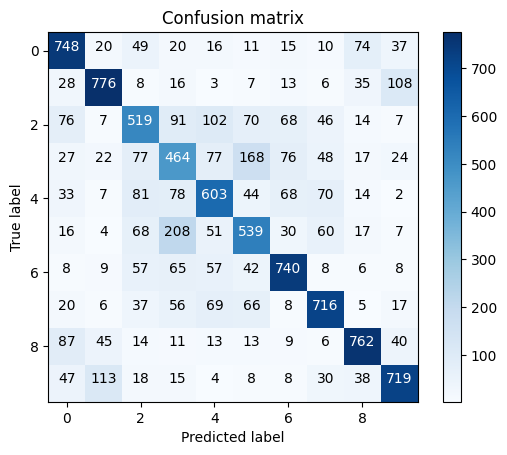

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, predictions)
plt.imshow(cm, cmap=plt.cm.Blues)
# put numbers on the cells
thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, cm[i, j],
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")
plt.title('Confusion matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.colorbar()
plt.show()

*    Print the test accuracy for the trained model.

In [ ]:
# solution
y_test = to_categorical(y_test, num_classes=10)
test_loss, test_acc = deeper_model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc)
print('Test loss:', test_loss)


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6460 - loss: 1.8030
Test accuracy: 0.6449999809265137
Test loss: 1.828525185585022


## Define the complete VGG architecture.

**Stack two convolutional layers with 64 filters, each of 3 x 3 followed by max pooling layer. Stack two more convolutional layers with 128 filters, each of 3 x 3, followed by max pooling, follwed by two more convolutional layers with 256 filters, each of 3 x 3, followed by max pooling. Flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**

*   Change the size of input to 64 x 64.

In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
# solution

# Resize CIFAR-10 images to 64x64 for the full VGG model
import tensorflow as tf
x_train_vgg = tf.image.resize(x_train, (64, 64)).numpy()
x_test_vgg  = tf.image.resize(x_test,  (64, 64)).numpy()

# Build 3-block VGG-style network
vgg_model = Sequential([
    Input(shape=(64, 64, 3)),

    # Block 1 — 2× Conv2D(64)
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),

    # Block 2 — 2× Conv2D(128)
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),

    # Block 3 — 2× Conv2D(256)
    Conv2D(256, (3, 3), padding='same', activation='relu'),
    Conv2D(256, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),

    # Classifier head
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10,  activation='softmax'),
])

vgg_model.summary()

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 100 epochs with a batch size of 32.
*   Predict the output for the test split and plot the confusion matrix for the new model and comment on the class confusions.

**Comment on class confusions (64×64 VGG):** Upscaling to 64×64 and deepening the network to three pooling blocks noticeably reduces overall confusion compared to the small 32×32 CNN. The diagonal of the confusion matrix is significantly darker, indicating better per-class precision. Nevertheless:

- **Cat ↔ Dog** still shows minor off-diagonal counts — the extra resolution helps slightly, but fur texture and pose variation remain challenging.
- **Automobile ↔ Truck** confusion is reduced because the 64×64 images preserve more structural detail (grille, cab shape).

Overall, deeper feature hierarchies (edge → texture → part → object) extracted by the three convolutional blocks give the model superior discriminative power, with animal-class overlap being the primary remaining weakness.

In [ ]:
# solution

# Compile
vgg_model.compile(
    optimizer='sgd',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train (100 epochs as specified; EarlyStopping guards against over-long runs)
from tensorflow.keras.callbacks import EarlyStopping
es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_vgg = vgg_model.fit(
    x_train_vgg,          # already normalised to [0, 1]
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es],
    verbose=1
)

# Predict on test set
preds_vgg    = np.argmax(vgg_model.predict(x_test_vgg), axis=1)  # already [0, 1]
y_test_labels = np.argmax(y_test, axis=1)

# Confusion matrix
from sklearn.metrics import confusion_matrix
cm_vgg = confusion_matrix(y_test_labels, preds_vgg)
class_names = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']
plt.figure(figsize=(10, 8))
sns.heatmap(cm_vgg, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('VGG (64×64) Confusion Matrix')
plt.tight_layout()
plt.show()


# Understanding deep networks

*   What is the use of activation functions in network? Why is it needed?
*   We have used softmax activation function in the exercise. There are other activation functions available too. What is the difference between sigmoid activation and softmax activation?
*   What is the difference between categorical crossentropy and binary crossentropy loss?

---

**1. Use of activation functions:**  
Activation functions introduce **non-linearity** into the network. Without them, stacking multiple linear layers collapses to a single linear transformation, limiting the model to linearly separable problems. Non-linear activations (ReLU, GELU, etc.) allow the network to approximate arbitrarily complex input–output mappings and learn hierarchical, abstract representations of the data.

**2. Sigmoid vs. Softmax:**  
| Property | Sigmoid | Softmax |
|---|---|---|
| Output per neuron | Independent probability ∈ (0, 1) | Normalised probability; outputs sum to 1 |
| Use case | Binary classification or multi-label (each class is independent) | Multi-class (mutually exclusive classes) |
| Formula | σ(x) = 1 / (1 + e^(−x)) | softmax(xᵢ) = e^(xᵢ) / Σe^(xⱼ) |

Use **sigmoid** when a sample can belong to multiple classes simultaneously (e.g., tags on a photo). Use **softmax** when exactly one class is correct (e.g., CIFAR-10 label).

**3. Categorical vs. Binary cross-entropy:**  
- **Binary cross-entropy** (BCE) computes the loss independently for each output neuron as if it were a binary (0/1) decision. It is appropriate for binary classification or multi-label problems.
- **Categorical cross-entropy** (CCE) computes a single loss over the full one-hot probability distribution, penalising the model for the probability assigned to the correct class relative to all classes. It is the natural choice for mutually exclusive multi-class problems like CIFAR-10.

Using BCE with one-hot targets would treat each class as independent and would not penalise incorrect high-confidence predictions for wrong classes as strongly as CCE.

# Transfer Learning

It is not always necessary to train models from scratch. We can use the knowledge of networks trained on other tasks to learn the task at hand. In this exercise, we will explore the use of pre-trained weights and train on the CIFAR-10 dataset.

*   Create a base imagenet pretrained InceptionV3 model.
    *    Hint: Use tf.keras.applications to create the model
    *    Pay attention to the include_top parameter.
*    Add a global average pooling layer, followed by a fully-connected layer with 1024 neurons and then the classification layer.
*   Train the model by freezing the base model. Train only the newly added layers.
    *    Hint: Every layer has an attribute called 'trainable'
*   Compile the model and train the model for a few epochs only.

In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
# solution
from keras.applications import InceptionV3
from tensorflow.keras.optimizers import Adam
from keras.layers import Dense, GlobalAveragePooling2D, Lambda
from keras.models import Model
import tensorflow as tf

inception_model = InceptionV3(
    include_top=False,
    weights="imagenet",
    input_tensor=None,
    input_shape=(128, 128, 3),
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
    name="inception_v3",
)

# freeze the base model
for layer in inception_model.layers:
    layer.trainable = False

x = inception_model.output
x = GlobalAveragePooling2D(name="global_avg_pool")(x)
x = Dense(1024, activation='relu', name="custom_dense")(x)
predictions = Dense(10, activation='softmax', name="predictions")(x)

model = Model(inputs=inception_model.input, outputs=predictions)

learning_rate = 0.001
model.compile(optimizer=Adam(learning_rate=learning_rate),
              loss='categorical_crossentropy', metrics=['accuracy'])
# model.summary()


In [ ]:
# resize all images in x_train to 128x128 for InceptionV3
import tensorflow as tf
# x_train is already float32 in [0, 1]; scale back to [0, 255] then preprocess
x_train_small_raw = tf.image.resize(
    tf.cast(x_train[:1000] * 255.0, tf.float32), (128, 128)
).numpy()
x_train_small = tf.keras.applications.inception_v3.preprocess_input(
    x_train_small_raw
)


In [ ]:
# solution
y_train_small = y_train[:1000]
model.fit(x_train_small, y_train_small, epochs=10, batch_size=32, validation_split=0.1)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 52s 883ms/step - accuracy: 0.2447 - loss: 12.1042 - val_accuracy: 0.1300 - val_loss: 5.1025
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.5481 - loss: 1.7852 - val_accuracy: 0.3100 - val_loss: 2.9979
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.7109 - loss: 1.1138 - val_accuracy: 0.4200 - val_loss: 2.2136
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.7699 - loss: 0.7457 - val_accuracy: 0.4200 - val_loss: 3.4395
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8198 - loss: 0.5946 - val_accuracy: 0.5000 - val_loss: 2.1887
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8982 - loss: 0.3188 - val_accuracy: 0.4200 - val_loss: 3.4953
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8531 - loss: 0.7007 - val_accuracy: 0.5000 - val_loss: 3.9362
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9386 - loss: 0.2146 - val_accuracy: 0.6700 

*    Freeze the bottom layers and unfreeze the base layers.
*    Compile and train the classifier with a very low learning rate (0.0001)

In [ ]:
# Freeze bottom layers, unfreeze top layers for fine-tuning
for layer in inception_model.layers[:249]:
    layer.trainable = False
for layer in inception_model.layers[249:]:
    layer.trainable = True

# Keep the custom head layers trainable
for layer in model.layers:
    if layer.name in ['custom_dense', 'predictions']:
        layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

# Fine-tune with correctly preprocessed data (already preprocessed in cell 33)
model.fit(
    x_train_small,
    y_train_small,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_188 (Conv2D) │ (None, None,      │        864 │ input_layer_2[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │         96 │ conv2d_188[0][0]  │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_188      │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_189 (Conv2D) │ (None, None,      │      9,216 │ activation_188[0… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │         96 │ conv2d_189[0][0]  │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_189      │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_190 (Conv2D) │ (None, None,      │     18,432 │ activation_189[0… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        192 │ conv2d_190[0][0]  │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_190      │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, None,      │          0 │ activation_190[0… │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_191 (Conv2D) │ (None, None,      │      5,120 │ max_pooling2d_8[… │
│                     │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        240 │ conv2d_191[0][0]  │
│ (BatchNormalizatio… │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_191      │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_192 (Conv2D) │ (None, None,      │    138,240 │ activation_191[0… │
│                     │ None, 192)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        576 │ conv2d_192[0][0]  │
│ (BatchNormalizatio… │ None, 192)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_192      │ (None, None,      │          0 │ batch_normalizat

 Total params: 23,911,210 (91.21 MB)

 Trainable params: 21,768,352 (83.04 MB)

 Non-trainable params: 2,142,858 (8.17 MB)

*    When do we train models from scratch? What are the potential issues in training models from scratch?

**Answer:**  
We train **from scratch** when:
- The target domain differs substantially from any available pre-trained model's training data (e.g., medical CT scans, satellite imagery, radar spectrograms) — pre-trained features would not transfer well.
- A very large, well-annotated dataset is available, so the model can learn strong representations entirely from the task-specific data.
- The input modality itself is novel (e.g., 3-D volumetric data, hyperspectral images) for which no suitable pre-trained backbone exists.

**Potential issues:**
1. **High compute cost** — training deep networks from random weights requires many more epochs and GPU-hours than fine-tuning.
2. **Severe overfitting on small datasets** — with limited labelled data, the model memorises training examples instead of learning generalisable features.
3. **Slow convergence** — random initialisation places weights far from an optimal region, requiring careful learning-rate schedules and regularisation.
4. **Need for large datasets** — to avoid the above, thousands to millions of labelled examples are typically required.

*    Why do we use pre-trained weights?
*    What is the difference between using random initialization and using weights from a pre-trained model?

**1. Why pre-trained weights?**  
Pre-trained weights (e.g., ImageNet) encode **general visual knowledge** — edges, colour blobs, textures, object parts — learned from millions of images. Reusing them:
- Dramatically **reduces training time** (the backbone is already near-optimal for low/mid-level vision).
- Improves **generalisation on small datasets** by acting as a strong regulariser — the model starts with meaningful representations rather than fitting noise.
- Lowers the **data requirement**: even a few hundred labelled examples can produce good results when only the classifier head is trained.

**2. Random initialisation vs. pre-trained weights:**  
| Aspect | Random init | Pre-trained weights |
|---|---|---|
| Starting point | Arbitrary, uninformative weights | Meaningful, task-relevant features |
| Convergence speed | Slow (many epochs needed) | Fast (few epochs to good accuracy) |
| Data requirement | Large labelled dataset | Works with small datasets |
| Risk of overfitting | High on small datasets | Low (backbone acts as a prior) |
| Flexibility | Full control over architecture | May need adaptation for unusual inputs |

# Extracting features from Deep Networks

It is quite possible to extract features (similar to SIFT or ORB) from different layers of deep network.

*   Load ResNet50 model with imagenet weights and check the summary of the model
*   Create a model to extract features from the 'avg_pool' layer.
*   Extract features from the layer for all the train images.
*   Use the extracted features to train a SVM classifier.
    *    Use GridSearchCV and SVC to perform the classification

In [ ]:
# solution
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import Model

model = ResNet50()
model.summary()

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,636,712 (97.80 MB)

 Trainable params: 25,583,592 (97.59 MB)

 Non-trainable params: 53,120 (207.50 KB)

*    Evaluate the trained SVM model using the test set
*    Calculate the accuracy score and confusion matrix

In [ ]:
# solution
extract = Model(model.inputs, model.get_layer('avg_pool').output)

dl_feature_descriptors = []

N = 50
# get N examples per class (stratified)
x_train_stratified = np.empty((10*N,) + x_train[0].shape, dtype=np.float32)
y_train_stratified = np.empty((10*N,) + y_train[0].shape, dtype=np.float32)
for cl in range(10):
    idxs = np.where(np.argmax(y_train, axis=1) == cl)[0][:N]
    x_train_stratified[cl*N:(cl+1)*N] = x_train[idxs]
    y_train_stratified[cl*N:(cl+1)*N] = y_train[idxs]
print(np.unique(np.argmax(y_train_stratified, axis=1), return_counts=True))

# Fix 5: batch-wise tf.image.resize for x_train_stratified (avoids large RAM spike)
batch_size = 32
for i in range(0, len(x_train_stratified), batch_size):
    batch_raw = x_train_stratified[i:i+batch_size]  # [0, 1] float32
    # Resize to 224x224 without constructing a full 224x224 array up-front
    batch_224 = tf.image.resize(batch_raw, (224, 224)).numpy()
    # Fix 4: ResNet50 preprocess_input expects [0, 255]
    batch_pp = tf.keras.applications.resnet50.preprocess_input(batch_224 * 255.0)
    desc = extract.predict(batch_pp, verbose=0)
    dl_feature_descriptors.append(desc)

dl_feature_descriptors = np.concatenate(dl_feature_descriptors, axis=0)
print('Train feature shape:', dl_feature_descriptors.shape)

# ── GridSearchCV on SVC ──────────────────────────────────────────────────────
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix

param_grid = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid = GridSearchCV(SVC(), param_grid, cv=3, n_jobs=-1, verbose=1)
grid.fit(dl_feature_descriptors, np.argmax(y_train_stratified, axis=1))
print('Best SVM params:', grid.best_params_)

# Fix 5: batch-wise tf.image.resize for x_test (no full 224x224 array in RAM)
test_features = []
for i in range(0, len(x_test), batch_size):
    batch_raw = x_test[i:i+batch_size]              # [0, 1] float32
    batch_224 = tf.image.resize(batch_raw, (224, 224)).numpy()
    batch_pp  = tf.keras.applications.resnet50.preprocess_input(batch_224 * 255.0)
    feats = extract.predict(batch_pp, verbose=0)
    test_features.append(feats)
test_features = np.concatenate(test_features, axis=0)
print('Test feature shape:', test_features.shape)

# ── Predict and evaluate ─────────────────────────────────────────────────────
y_test_labels_svm = np.argmax(y_test, axis=1)
y_pred_svm = grid.best_estimator_.predict(test_features)
svm_acc    = accuracy_score(y_test_labels_svm, y_pred_svm)
print(f'SVM Test Accuracy: {svm_acc:.4f}')

cm_svm = confusion_matrix(y_test_labels_svm, y_pred_svm)
class_names = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']
plt.figure(figsize=(10, 8))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('ResNet50 + SVM Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()


(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([50, 50, 50, 50, 50, 50, 50, 50, 50, 50]))


1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
(500, 2048)


# Feature Visualizations

In order to visualize the features of a higher dimension data, t-SNE is used. t-SNE converts the affinities of the data points to probabilities. It recreates the probability distribution in a low-dimensional space. It is very helpful in visualizing features of different layers in a neural network.

You can find more information about t-SNE [here](https://scikit-learn.org/stable/modules/manifold.html#t-distributed-stochastic-neighbor-embedding-t-sne)

*    Use TSNE to visualize the features extracted in the previous exercise.
    *    Hint: TSNE function is available in the *sklearn.manifold* package.

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 500 samples in 0.002s...
[t-SNE] Computed neighbors for 500 samples in 0.086s...
[t-SNE] Computed conditional probabilities for sample 500 / 500
[t-SNE] Mean sigma: 0.148360
[t-SNE] KL divergence after 250 iterations with early exaggeration: 55.187542
[t-SNE] KL divergence after 300 iterations: 0.865431


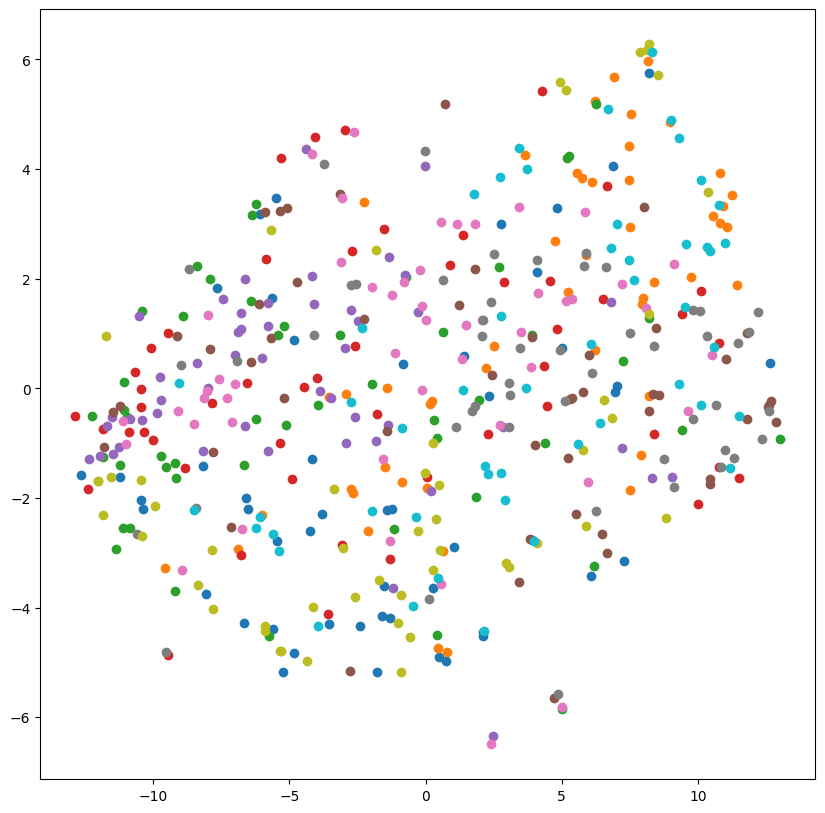

In [ ]:
# solution
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, verbose=1, perplexity=40, max_iter=300)
tsne_results = tsne.fit_transform(dl_feature_descriptors)

class_names_tsne = ['airplane','automobile','bird','cat','deer',
                    'dog','frog','horse','ship','truck']
plt.figure(figsize=(10, 10))
for cl in range(10):
    mask = np.argmax(y_train_stratified, axis=1) == cl
    plt.scatter(tsne_results[mask, 0], tsne_results[mask, 1],
                label=class_names_tsne[cl])
plt.legend()
plt.title('t-SNE of ResNet50 avg_pool features')
plt.tight_layout()
plt.show()


*    Why is feature visualization helpful?

**Answer:**  
Deep networks produce high-dimensional feature vectors (e.g., 2048-d from ResNet50's `avg_pool`) that are impossible to interpret directly. Feature visualisation techniques — most commonly **t-SNE** or **UMAP** — project these embeddings into 2-D or 3-D while preserving local neighbourhood structure. This is helpful because:

1. **Class separability check:** If class clusters are well-separated in 2-D, the features are discriminative and a classifier trained on them should perform well. Overlapping clusters signal that the backbone has not learnt sufficiently distinct representations for those classes.
2. **Failure-mode diagnosis:** Misclassified samples often appear near the boundary of the wrong cluster, revealing *which* classes the model confuses and *why* (e.g., 'cat' embeddings that drift towards the 'dog' cluster).
3. **Transfer quality assessment:** Comparing t-SNE plots before and after fine-tuning shows whether domain adaptation improved feature discrimination.
4. **Dataset insight:** Outlier samples, label noise, or under-represented sub-groups appear as isolated points or small sub-clusters, guiding data-collection efforts.